# 3. Mode decomposition

An AR(p) fit returns $p$ coefficients.  A single coefficient has no
interpretation as a timescale; the roots of the characteristic polynomial do.

The characteristic polynomial $z^p - \varphi_1 z^{p-1} - \cdots - \varphi_p$
has $p$ roots.  Each root $\lambda$ gives a decay time and a frequency,

$$\tau = \frac{-1/f_s}{\log|\lambda|}, \qquad
  f = \frac{f_s\,|\arg \lambda|}{2\pi}$$

A real root has $f = 0$ and is a decay.  Complex roots occur in conjugate
pairs, each pair giving one damped oscillation.  These are the modes of the
model, returned by `decompose()` ranked by importance.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from timescales import ARPSD, compute_psd
from timescales.sim import ARpModes

plt.rcParams.update({'figure.figsize': (10, 3.5), 'font.size': 11})
fs = 500.

## Recovering constructed modes

A process is built from known modes, simulated, fit, and decomposed.

In [2]:
true_modes = ((0.2, 0.), (0.15, 10.), (0.06, 40.), (0.02, 0.))
proc = ARpModes(modes=true_modes)
print(f'constructed order: {len(proc.phi(fs))}')

sig = proc.simulate(400., fs, np.random.default_rng(0))
freqs, powers = compute_psd(sig, fs, nperseg=int(4 * fs), f_range=(0.5, 250))

ar = ARPSD(order=range(1, 13), fs=fs).fit(freqs, powers)
modes = ar.decompose()
print(f'fitted order:      {ar.order_}\n')
print(modes)

constructed order: 6


fitted order:      6

ARModes(order=6, fs=500, stationary=True)
  0. Mode(oscillatory, tau=0.1423s, f=9.99Hz, 1.42 cyc, |lam|=0.9860, importance=1.433)
  1. Mode(oscillatory, tau=0.05947s, f=40.01Hz, 2.38 cyc, |lam|=0.9669, importance=1.136)
  2. Mode(relaxation, tau=0.2021s, f=0Hz, |lam|=0.9902, importance=0.7487)
  3. Mode(relaxation, tau=0.02014s, f=0Hz, |lam|=0.9055, importance=0.6443)


Each mode has a kind, a decay time, a frequency and an importance.
Importance is the root-mean-square change in the model log spectrum when the
mode is deleted and the overall scale refit.  Per-mode variance shares are
undefined: all modes are driven by the same innovation sequence, so their
contributions to the process variance are not independent.

In [3]:
print(f'{"kind":<12}{"tau (ms)":>10}{"freq (Hz)":>11}{"importance":>12}')
for m in modes.modes:
    print(f'{m.kind:<12}{m.tau * 1e3:10.1f}{m.freq:11.1f}{m.importance:12.3f}')

print('\nconstructed:')
for tau, f in sorted(true_modes, key=lambda t: -t[0]):
    print(f'{"":12}{tau * 1e3:10.1f}{f:11.1f}')

kind          tau (ms)  freq (Hz)  importance
oscillatory      142.3       10.0       1.433
oscillatory       59.5       40.0       1.136
relaxation       202.1        0.0       0.749
relaxation        20.1        0.0       0.644

constructed:
                 200.0        0.0
                 150.0       10.0
                  60.0       40.0
                  20.0        0.0


## How modes combine

The two domains combine modes differently.  In the lag domain each mode
contributes one exponential or one damped cosine and the components sum to the
model autocorrelation.  In the spectrum each mode contributes a factor
$1/|1 - \lambda z^{-1}|^2$, and the factors multiply, so on a logarithmic
axis they add.  Each factor below is drawn relative to its geometric mean over
the band, which removes the arbitrary split of the overall scale between them.

The partial-fraction components of the spectrum are additive and sum to the
fit.  For an oscillatory mode they are negative over most of the band, which
puts them outside the range of a logarithmic axis.

ACF components sum to the model ACF: True
PSD factors multiply to the model PSD: True
PSD partial fractions sum to the model PSD: True
  oscillatory  negative at  95.0% of bins
  oscillatory  negative at  82.5% of bins
  relaxation   negative at   0.0% of bins
  relaxation   negative at 100.0% of bins


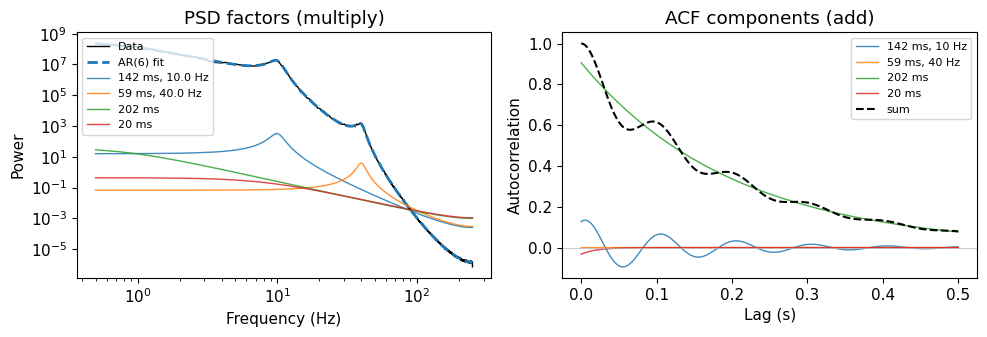

In [4]:
fig, axes = plt.subplots(1, 2)
ar.plot(ax=axes[0], plot_modes=True, title='PSD factors (multiply)')

nlags = 250
comps = modes.acf_components(nlags)
lags = np.arange(nlags + 1) / fs
for comp, m in zip(comps, modes.modes):
    label = (f'{m.tau * 1e3:.0f} ms' if m.kind == 'relaxation'
             else f'{m.tau * 1e3:.0f} ms, {m.freq:.0f} Hz')
    axes[1].plot(lags, comp, lw=1, alpha=.85, label=label)
axes[1].plot(lags, comps.sum(axis=0), 'k--', lw=1.5, label='sum')
axes[1].axhline(0, color='.7', lw=.5)
axes[1].set(xlabel='Lag (s)', ylabel='Autocorrelation',
            title='ACF components (add)')
axes[1].legend(fontsize=8)
fig.tight_layout()

# the ACF components add to the model ACF
print('ACF components sum to the model ACF:',
      np.allclose(comps.sum(axis=0), modes.acf(nlags), atol=1e-6))

# the PSD factors multiply to the model PSD, up to the overall scale
factors = np.prod([m.psd(freqs) for m in modes.modes], axis=0)
scale = np.exp(np.mean(np.log(ar.predict()) - np.log(factors)))
print('PSD factors multiply to the model PSD:',
      np.allclose(scale * factors, ar.predict(), rtol=1e-8))

# the partial-fraction components are additive but go negative
psd_comps = modes.psd_components(freqs)
print('PSD partial fractions sum to the model PSD:',
      np.allclose(psd_comps.sum(axis=0), ar.predict(), rtol=1e-6))
for comp, m in zip(psd_comps, modes.modes):
    print(f'  {m.kind:<12} negative at {100 * np.mean(comp < 0):5.1f}% of bins')

## Reported timescale

`tau` returns the highest importance mode with $f\tau < 1$, that is, a mode
that decays before completing one cycle.  Modes completing more than one cycle
are rhythms and are excluded.

In [5]:
print(f'tau (aperiodic)  {ar.tau * 1e3:.1f} ms')
print(f'tau_dominant     {ar.tau_dominant * 1e3:.1f} ms')
print(f'all taus (ms)    {np.round(ar.taus * 1e3, 1)}')
print(f'frequencies (Hz) {np.round(ar.freqs_hz, 1)}')

print(f'\n{"mode":<28}{"cycles before decay":>20}')
for m in modes.modes:
    print(f'{repr(m)[:27]:<28}{m.n_cycles:20.2f}')

tau (aperiodic)  202.1 ms
tau_dominant     142.3 ms
all taus (ms)    [142.3  59.5 202.1  20.1]
frequencies (Hz) [10. 40.  0.  0.]

mode                         cycles before decay
Mode(oscillatory, tau=0.142                 1.42
Mode(oscillatory, tau=0.059                 2.38
Mode(relaxation, tau=0.2021                 0.00
Mode(relaxation, tau=0.0201                 0.00


## Number of modes required

`dominant_subset` returns the smallest set of modes reproducing the fitted log
spectrum to a given $R^2$.  For this fit all four modes are required at
$R^2 = 0.99$; the curve below gives the $R^2$ reached by the best subset of
each size.

4 of 4 modes reproduce the fit
kept: ['142 ms', '59 ms', '202 ms', '20 ms']


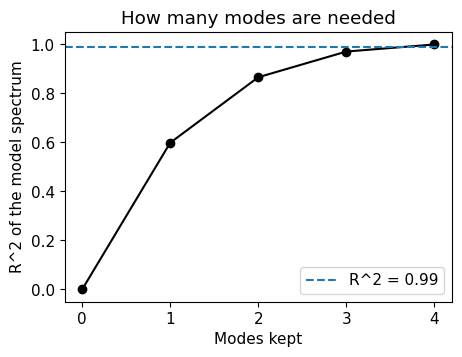

In [6]:
sub = modes.dominant_subset(tol=0.1)      # R^2 >= 0.99 of the model spectrum
print(f'{sub["n_modes"]} of {len(modes.modes)} modes reproduce the fit')
print(f'kept: {[f"{modes.modes[i].tau * 1e3:.0f} ms" for i in sub["indices"]]}')

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(range(len(sub['r2_curve'])), sub['r2_curve'], 'o-', color='k')
ax.axhline(0.99, color='C0', ls='--', label='R^2 = 0.99')
ax.set(xlabel='Modes kept', ylabel='R^2 of the model spectrum',
       title='How many modes are needed')
ax.legend();

Tutorial 4 applies the same three calls to eight recordings.